# **Installing Required  Libarey**

In [ ]:
!pip install catboost==1.2.2
!pip install shap
!pip install lime
!pip install imbalanced-learn
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=540a1f133a057ba8ff51b00c22b31d7d33702ecfcb03725fa74f04defc53338c
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


# **Importing Required Library**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score ,confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
import xgboost as xgb
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold
import os
import time
from seaborn import heatmap
import seaborn as sns
from sklearn.ensemble import VotingClassifier
import shap
from lime import lime_tabular

import catboost
from catboost import *
import shap
shap.initjs()

# **Importing Dataset**

In [ ]:

dt=pd.read_csv("/content/career_preferences_dataset(updated).csv")
dt.drop(["Timestamp"],axis=1,inplace=True)

dt

,What is planning as a profession?,What are the primary factors influencing your career choice?,How likely are you to pursue entrepreneurship as a career path after graduation?,Which type of career are you most interested in pursuing?,How much does family influence your career decision?,To what extent do internships or practical experience influence your career choice?,Which of the following work environments do you prefer?,How important is work-life balance in your career choice?,What role does salary play in your career decision-making process?,How confident are you that your university education has prepared you for your preferred career?,"If given the option, would you prefer a career that allows for remote or flexible work arrangements?",How important is job security in your career decision-making?,How interested are you in pursuing a career in a family business?,What type of work environment do you feel most productive in?,What is the most important factor in choosing between a corporate job and starting a business?,How much importance do you place on finding a job with a strong reputation and societal status?
0,Job,Job security and stability,Neutral,Corporate job in a large company,Very influential,Very influential,Structured and stable corporate environment,Very important,It is moderately important,Neutral,Prefer,Slightly important,Not interested at all,Flexible startup culture,Career growth opportunities,Very important
1,Job,Job security and stability,Unlikely,Starting my own business,Neutral,Very influential,Structured and stable corporate environment,Very important,It is moderately important,Very confident,Prefer,Slightly important,Somewhat interested,Structured corporate environment,Financial stability,Moderately important
2,Job,Job security and stability,Neutral,Government job,Neutral,Little influence,Flexible and innovative startup culture,Moderately important,It is not important,Very confident,Prefer,Very important,Not interested at all,Self-directed (entrepreneurship),Flexibility and autonomy,Very important
3,Business,Work-life balance,Very likely,Corporate job in a large company,Very influential,Very influential,Flexible and innovative startup culture,Very important,It is the most important factor,Neutral,Prefer,Very important,Not very interested,Flexible startup culture,Financial stability,Moderately important
4,Job,Personal growth and development opportunities,Neutral,Government job,Very influential,Neutral,Flexible and innovative startup culture,Very important,It is moderately important,Very confident,Prefer,Slightly important,Very interested,Flexible startup culture,Flexibility and autonomy,Very important
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,Business,Job security and stability,Neutral,Corporate job in a large company,Neutral,Little influence,Independent and self-directed (entrepreneurship),Moderately important,It is the most important factor,Very confident,Neutral,Slightly important,Somewhat interested,Structured corporate environment,Flexibility and autonomy,Very important
346,Job,Job security and stability,Neutral,Corporate job in a large company,Very influential,Little influence,Structured and stable corporate environment,Very important,It is the most important factor,Neutral,Neutral,Slightly important,Neutral,Structured corporate environment,Flexibility and autonomy,Very important
347,Job,Job security and stability,Very likely,Corporate job in a large company,No influence at all,Neutral,Structured and stable corporate environment,Moderately important,It is moderately important,Very confident,Prefer,Very important,Somewhat interested,Structured corporate environment,Flexibility and autonomy,Very important
348,Business,Personal growth and development opportunities,Neutral,Corporate job in a large company,Neutral,Neutral,Structured and stable corporate environment,Moderately important,It is the most important factor,Not very confident,Prefer,Very important,Not very inter

# **Pre-Processing**

In [ ]:
dt.isnull().sum()

,0
What is planning as a profession?,0
What are the primary factors influencing your career choice?,0
How likely are you to pursue entrepreneurship as a career path after graduation?,0
Which type of career are you most interested in pursuing?,0
How much does family influence your career decision?,0
To what extent do internships or practical experience influence your career choice?,0
Which of the following work environments do you prefer?,0
How important is work-life balance in your career choice?,0
What role does salary play in your career decision-making process?,0
How confident are you that your university education has prepared you for your preferred career?,0


In [ ]:

dt.dropna(inplace=True)
dt

,What is planning as a profession?,What are the primary factors influencing your career choice?,How likely are you to pursue entrepreneurship as a career path after graduation?,Which type of career are you most interested in pursuing?,How much does family influence your career decision?,To what extent do internships or practical experience influence your career choice?,Which of the following work environments do you prefer?,How important is work-life balance in your career choice?,What role does salary play in your career decision-making process?,How confident are you that your university education has prepared you for your preferred career?,"If given the option, would you prefer a career that allows for remote or flexible work arrangements?",How important is job security in your career decision-making?,How interested are you in pursuing a career in a family business?,What type of work environment do you feel most productive in?,What is the most important factor in choosing between a corporate job and starting a business?,How much importance do you place on finding a job with a strong reputation and societal status?
0,Job,Job security and stability,Neutral,Corporate job in a large company,Very influential,Very influential,Structured and stable corporate environment,Very important,It is moderately important,Neutral,Prefer,Slightly important,Not interested at all,Flexible startup culture,Career growth opportunities,Very important
1,Job,Job security and stability,Unlikely,Starting my own business,Neutral,Very influential,Structured and stable corporate environment,Very important,It is moderately important,Very confident,Prefer,Slightly important,Somewhat interested,Structured corporate environment,Financial stability,Moderately important
2,Job,Job security and stability,Neutral,Government job,Neutral,Little influence,Flexible and innovative startup culture,Moderately important,It is not important,Very confident,Prefer,Very important,Not interested at all,Self-directed (entrepreneurship),Flexibility and autonomy,Very important
3,Business,Work-life balance,Very likely,Corporate job in a large company,Very influential,Very influential,Flexible and innovative startup culture,Very important,It is the most important factor,Neutral,Prefer,Very important,Not very interested,Flexible startup culture,Financial stability,Moderately important
4,Job,Personal growth and development opportunities,Neutral,Government job,Very influential,Neutral,Flexible and innovative startup culture,Very important,It is moderately important,Very confident,Prefer,Slightly important,Very interested,Flexible startup culture,Flexibility and autonomy,Very important
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,Business,Job security and stability,Neutral,Corporate job in a large company,Neutral,Little influence,Independent and self-directed (entrepreneurship),Moderately important,It is the most important factor,Very confident,Neutral,Slightly important,Somewhat interested,Structured corporate environment,Flexibility and autonomy,Very important
346,Job,Job security and stability,Neutral,Corporate job in a large company,Very influential,Little influence,Structured and stable corporate environment,Very important,It is the most important factor,Neutral,Neutral,Slightly important,Neutral,Structured corporate environment,Flexibility and autonomy,Very important
347,Job,Job security and stability,Very likely,Corporate job in a large company,No influence at all,Neutral,Structured and stable corporate environment,Moderately important,It is moderately important,Very confident,Prefer,Very important,Somewhat interested,Structured corporate environment,Flexibility and autonomy,Very important
348,Business,Personal growth and development opportunities,Neutral,Corporate job in a large company,Neutral,Neutral,Structured and stable corporate environment,Moderately important,It is the most important factor,Not very confident,Prefer,Very important,Not very inter

In [ ]:
dt.isnull().sum()

,0
What is planning as a profession?,0
What are the primary factors influencing your career choice?,0
How likely are you to pursue entrepreneurship as a career path after graduation?,0
Which type of career are you most interested in pursuing?,0
How much does family influence your career decision?,0
To what extent do internships or practical experience influence your career choice?,0
Which of the following work environments do you prefer?,0
How important is work-life balance in your career choice?,0
What role does salary play in your career decision-making process?,0
How confident are you that your university education has prepared you for your preferred career?,0


# **Balance imbalance check**

# **Lebel Encoding**

In [ ]:

le = LabelEncoder()

for column in dt.columns:
    if dt[column].dtype == 'object' or dt[column].dtype.name == 'category':
        dt[column] = le.fit_transform(dt[column])
dt


,What is planning as a profession?,What are the primary factors influencing your career choice?,How likely are you to pursue entrepreneurship as a career path after graduation?,Which type of career are you most interested in pursuing?,How much does family influence your career decision?,To what extent do internships or practical experience influence your career choice?,Which of the following work environments do you prefer?,How important is work-life balance in your career choice?,What role does salary play in your career decision-making process?,How confident are you that your university education has prepared you for your preferred career?,"If given the option, would you prefer a career that allows for remote or flexible work arrangements?",How important is job security in your career decision-making?,How interested are you in pursuing a career in a family business?,What type of work environment do you feel most productive in?,What is the most important factor in choosing between a corporate job and starting a business?,How much importance do you place on finding a job with a strong reputation and societal status?
0,1,0,0,0,2,2,2,2,0,0,2,1,1,0,0,2
1,1,0,1,2,0,2,2,2,0,2,2,1,3,2,1,0
2,1,0,0,1,0,0,0,0,1,2,2,2,1,1,2,2
3,0,2,2,0,2,2,0,2,2,0,2,2,2,0,1,0
4,1,1,0,1,2,1,0,2,0,2,2,1,4,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,0,0,0,0,0,0,1,0,2,2,0,1,3,2,2,2
346,1,0,0,0,2,0,2,2,2,0,0,1,0,2,2,2
347,1,0,2,0,1,1,2,0,0,2,2,2,3,2,2,2
348,0,1,0,0,0,1,2,0,2,1,2,2,2,2,1,2


# **Data Balancing Using SMOTE**

In [ ]:


X = dt.drop('What is planning as a profession?', axis=1)
y = dt['What is planning as a profession?']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

resampled_data = pd.DataFrame(X_resampled, columns=X.columns)
resampled_data['What is planning as a profession?'] = y_resampled

dt = resampled_data

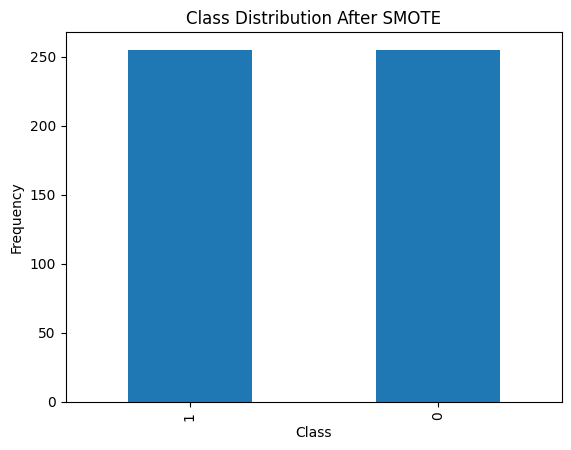

In [ ]:
dt['What is planning as a profession?'].value_counts().plot(kind='bar')
plt.title('Class Distribution After SMOTE')
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.show()


# **Feature Check**

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler

# Example Data
# Separate features and target variable
X = dt.drop('What is planning as a profession?', axis=1)
y = dt['What is planning as a profession?']

# Ensure features are non-negative for chi2 (use MinMaxScaler)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Test different values of k, ensure k is less than or equal to the number of features
max_features = X_scaled.shape[1]

for k in range(1, min(15, max_features + 1)):  # Ensure k is within the feature count
    selector = SelectKBest(score_func=chi2, k=k)
    X_selected = selector.fit_transform(X_scaled, y)

    # Evaluate with cross-validation
    model = RandomForestClassifier(random_state=42)
    scores = cross_val_score(model, X_selected, y, cv=5)
    print(f"k={k}, Mean Accuracy: {scores.mean():.4f}")



k=1, Mean Accuracy: 0.6000
k=2, Mean Accuracy: 0.6608
k=3, Mean Accuracy: 0.6902
k=4, Mean Accuracy: 0.6667
k=5, Mean Accuracy: 0.6902
k=6, Mean Accuracy: 0.6922
k=7, Mean Accuracy: 0.7196
k=8, Mean Accuracy: 0.7471
k=9, Mean Accuracy: 0.7451
k=10, Mean Accuracy: 0.7392
k=11, Mean Accuracy: 0.7471
k=12, Mean Accuracy: 0.7863
k=13, Mean Accuracy: 0.8098
k=14, Mean Accuracy: 0.8353


In [ ]:
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Example: Your dataset (replace `dt` with your actual DataFrame)
# dt = pd.read_csv('your_dataset.csv')

# Separate features and target variable
X = dt.drop('What is planning as a profession?', axis=1)
y = dt['What is planning as a profession?']

# Ensure no negative values (convert using Min-Max Scaling if necessary)
if (X < 0).any().any():
    print("Warning: Converting negative values to non-negative using Min-Max Scaling.")
    scaler = MinMaxScaler()
    X = scaler.fit_transform(X)
else:
    X = X.values  # Convert DataFrame to NumPy array

# Perform Chi-Square test
chi2_scores, p_values = chi2(X, y)

# Create a DataFrame to display feature scores
feature_scores = pd.DataFrame({
    'Feature': dt.drop('What is planning as a profession?', axis=1).columns,
    'Chi2 Score': chi2_scores,
    'P-value': p_values
}).sort_values(by='Chi2 Score', ascending=False)

print("Chi2 Scores for Features:")
print(feature_scores)

# Select top k features
k = 14  # Adjust 'k' based on your needs
top_features = SelectKBest(chi2, k=k).fit(X, y)

# Display top selected features
selected_features = dt.drop('What is planning as a profession?', axis=1).columns[top_features.get_support()]
print("\nTop Features Selected:")
print(selected_features)

# Create a new DataFrame with the top selected features and the target variable
top_features_list = selected_features.to_list()  # Convert selected features to a list
dt = dt[top_features_list + ['What is planning as a profession?']]  # Replace original DataFrame

# Display the new DataFrame
print("Updated DataFrame with Top Features:")
dt




Chi2 Scores for Features:
                                              Feature  Chi2 Score  \
1   How likely are you to pursue entrepreneurship ...   24.908108   
6   How important is work-life balance in your car...   20.519862   
3   How much does family influence your career dec...    9.777982   
14  How much importance do you place on finding a ...    6.451613   
2   Which type of career are you most interested i...    5.378049   
8   How confident are you that your university edu...    4.480730   
10  How important is job security in your career d...    4.000000   
13  What is the most important factor in choosing ...    3.932039   
7   What role does salary play in your career deci...    2.473171   
9   If given the option, would you prefer a career...    2.218801   
11  How interested are you in pursuing a career in...    1.901408   
5   Which of the following work environments do yo...    1.593698   
0   What are the primary factors influencing your ...    0.931034   
12  What

,What are the primary factors influencing your career choice?,How likely are you to pursue entrepreneurship as a career path after graduation?,Which type of career are you most interested in pursuing?,How much does family influence your career decision?,Which of the following work environments do you prefer?,How important is work-life balance in your career choice?,What role does salary play in your career decision-making process?,How confident are you that your university education has prepared you for your preferred career?,"If given the option, would you prefer a career that allows for remote or flexible work arrangements?",How important is job security in your career decision-making?,How interested are you in pursuing a career in a family business?,What type of work environment do you feel most productive in?,What is the most important factor in choosing between a corporate job and starting a business?,How much importance do you place on finding a job with a strong reputation and societal status?,What is planning as a profession?
0,0,0,0,2,2,2,0,0,2,1,1,0,0,2,1
1,0,1,2,0,2,2,0,2,2,1,3,2,1,0,1
2,0,0,1,0,0,0,1,2,2,2,1,1,2,2,1
3,2,2,0,2,0,2,2,0,2,2,2,0,1,0,0
4,1,0,1,2,0,2,0,2,2,1,4,0,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
505,0,0,0,0,2,0,0,1,2,2,2,2,1,1,0
506,0,0,1,2,2,1,0,0,2,0,2,0,1,0,0
507,0,0,0,1,0,0,2,0,1,2,0,2,1,0,0
508,0,0,0,0,2,0,2,1,0,2,2,2,1,0,0


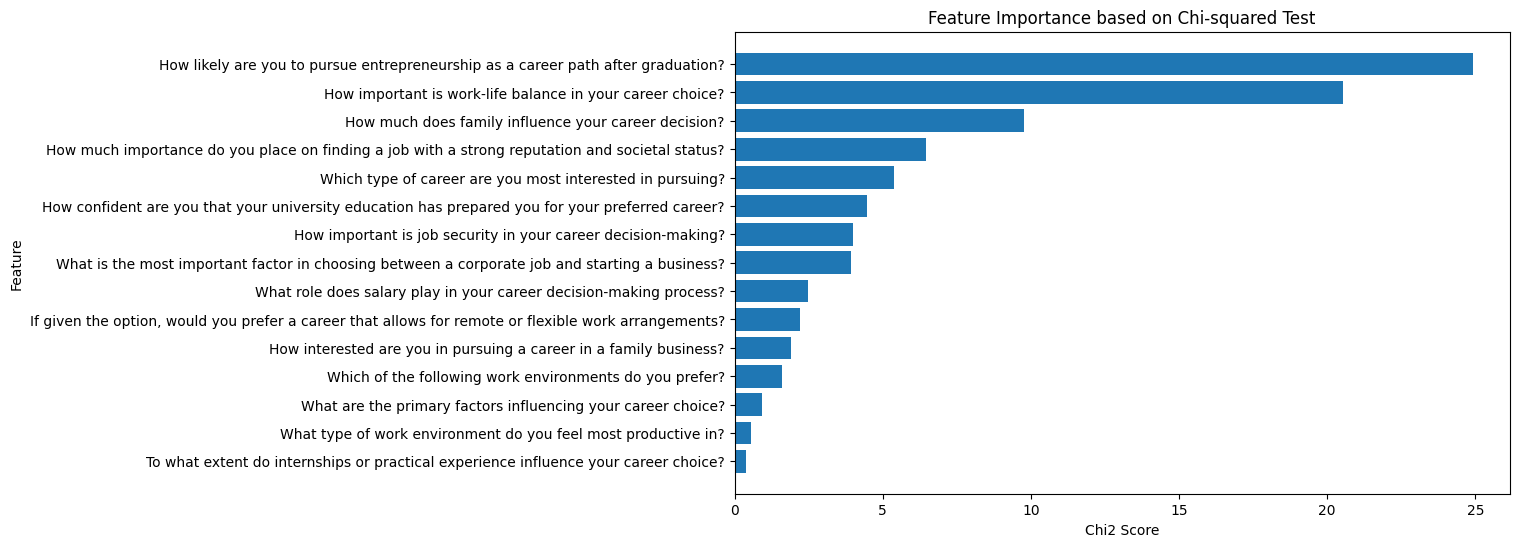

In [ ]:

plt.figure(figsize=(10, 6))
plt.barh(feature_scores['Feature'], feature_scores['Chi2 Score'])
plt.xlabel('Chi2 Score')
plt.ylabel('Feature')
plt.title('Feature Importance based on Chi-squared Test')
plt.gca().invert_yaxis()
plt.show()

# **Model Training**

In [ ]:



X = dt.drop('What is planning as a profession?', axis=1)
y = dt['What is planning as a profession?']
cat_features = list(range(0, X.shape[1]))
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1500),
    "Decision Tree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(),
    #"SVM": SVC(probability=True),
    "Gradient Boosting": GradientBoostingClassifier(),
    "CatBoost": CatBoostClassifier(loss_function = 'MultiClass',cat_features=cat_features, verbose=False),
    "XGBoost": xgb.XGBClassifier(eval_metric='mlogloss')
}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

classification_reports = {}
classification_model={}

print("\n=== Classification Models ===")
for model_name, model in classification_models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    classification_model[model_name]=model

    print("\nClassification Report:")
    report = classification_report(y_test, y_pred, zero_division=0)
    print(report)

    classification_reports[model_name] = classification_report(y_test, y_pred, output_dict=True, zero_division=0)



=== Classification Models ===

Training Logistic Regression...

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.60      0.58        50
           1       0.59      0.56      0.57        52

    accuracy                           0.58       102
   macro avg       0.58      0.58      0.58       102
weighted avg       0.58      0.58      0.58       102


Training Decision Tree...

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.76      0.74        50
           1       0.76      0.71      0.73        52

    accuracy                           0.74       102
   macro avg       0.74      0.74      0.74       102
weighted avg       0.74      0.74      0.74       102


Training KNN...

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.90      0.78        50
           1       0.86      0.60      0.70        52

  

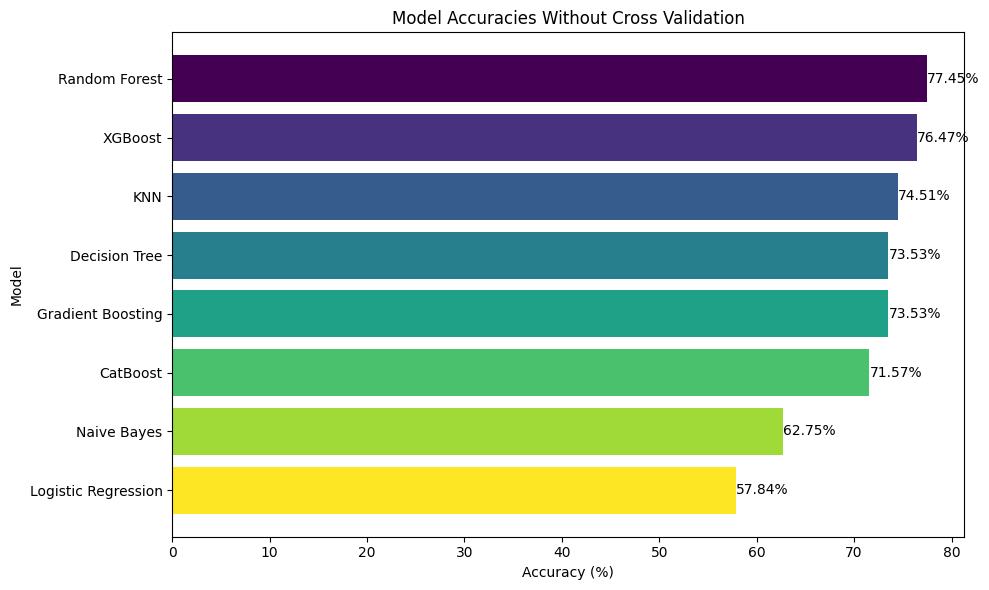

In [ ]:
model_accuracies = {}
for model_name, report in classification_reports.items():
    model_accuracies[model_name] = report['accuracy'] * 100  # Convert to percentage

sorted_models = dict(sorted(model_accuracies.items(), key=lambda item: item[1], reverse=True))

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_models)))
plt.barh(list(sorted_models.keys()), list(sorted_models.values()), color=colors)
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")
plt.title("Model Accuracies Without Cross Validation")

for index, value in enumerate(sorted_models.values()):
    plt.text(value, index, f"{value:.2f}%", va='center')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
import xgboost as xgb
import numpy as np

# Define classification models
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(),
    #"SVM": SVC(probability=True),
    "Gradient Boosting": GradientBoostingClassifier(),
    "CatBoost": CatBoostClassifier(verbose=0),
    "XGBoost": xgb.XGBClassifier()
}

classification_reports_Cross_Validation = {}
classification_model_Cress_ValidationK={}
accuracy_scores = {}
mean_accuracies = {}

# Define cross-validation strategy

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Train and evaluate classification models using cross-validation
print("\n=== Classification Models ===")
for model_name, model in classification_models.items():
    print(f"\nTraining {model_name} with Cross-Validation...")
    # Cross-validation scores for accuracy
    cv_scores = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')

    # Cross-validation predictions
    y_pred = cross_val_predict(model, X, y, cv=kfold)

    # Classification Report
    print(f"\nCross-Validation Accuracy Scores: {cv_scores}")
    print(f"Mean Accuracy: {cv_scores.mean():.4f}, Std Dev: {cv_scores.std():.4f}")
    print("\nClassification Report:")
    print(classification_report(y, y_pred, zero_division=0))

    # Save the report for further analysis
    classification_reports_Cross_Validation[model_name] = classification_report(y, y_pred, output_dict=True, zero_division=0)
    classification_model_Cress_ValidationK[model_name]=model
    accuracy_scores[model_name] = cv_scores
    mean_accuracies[model_name] = cv_scores.mean()



=== Classification Models ===

Training Logistic Regression with Cross-Validation...

Cross-Validation Accuracy Scores: [0.57843137 0.66666667 0.68627451 0.66666667 0.64705882]
Mean Accuracy: 0.6490, Std Dev: 0.0374

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.64      0.65       255
           1       0.65      0.65      0.65       255

    accuracy                           0.65       510
   macro avg       0.65      0.65      0.65       510
weighted avg       0.65      0.65      0.65       510


Training Decision Tree with Cross-Validation...

Cross-Validation Accuracy Scores: [0.74509804 0.79411765 0.74509804 0.67647059 0.6372549 ]
Mean Accuracy: 0.7196, Std Dev: 0.0557

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.76      0.74       255
           1       0.75      0.70      0.72       255

    accuracy                           0.73       510
   macro a

# **Visualising there Accuracy**

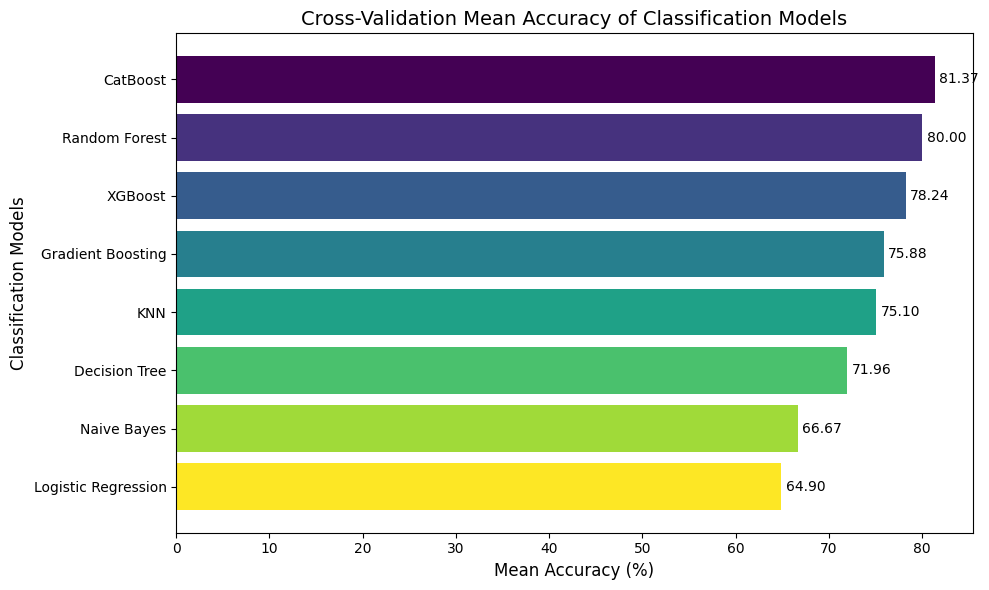

In [ ]:

model_names = list(accuracy_scores.keys())
mean_accuracy = [np.mean(scores) * 100 for scores in accuracy_scores.values()]

sorted_indices = np.argsort(mean_accuracy)[::-1]
sorted_model_names = [model_names[i] for i in sorted_indices]
sorted_mean_accuracy = [mean_accuracy[i] for i in sorted_indices]

colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_model_names)))

plt.figure(figsize=(10, 6))
plt.barh(sorted_model_names, sorted_mean_accuracy, color=colors)
plt.xlabel("Mean Accuracy (%)", fontsize=12)
plt.ylabel("Classification Models", fontsize=12)
plt.title("Cross-Validation Mean Accuracy of Classification Models", fontsize=14)

for i, v in enumerate(sorted_mean_accuracy):
    plt.text(v + 0.5, i, f"{v:.2f}", color='black', va='center')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

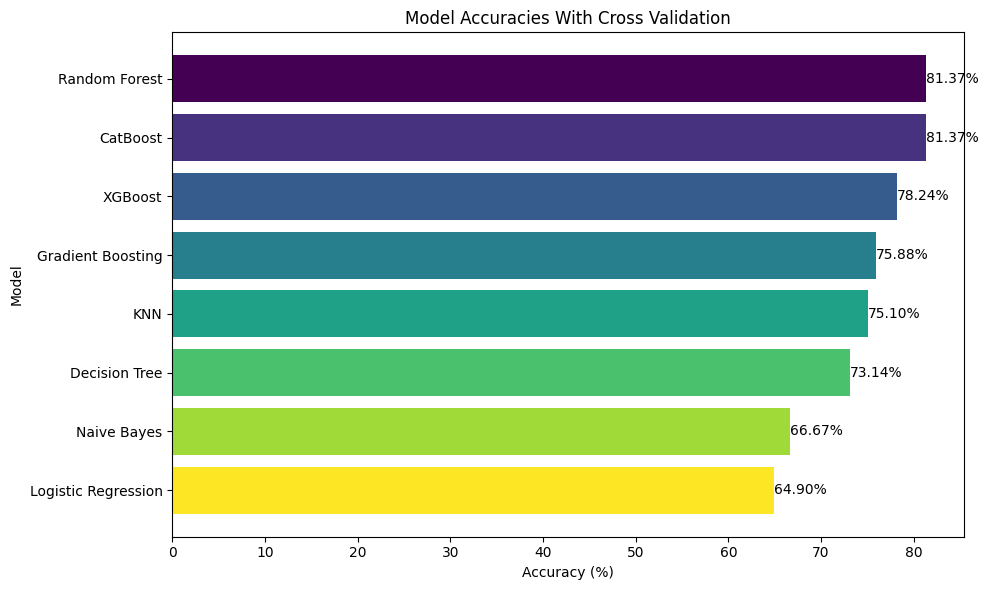

In [ ]:
model_accuracies = {}

for model_name, report in classification_reports_Cross_Validation.items():
    model_accuracies[model_name] = report['accuracy'] * 100

sorted_models = dict(sorted(model_accuracies.items(), key=lambda item: item[1], reverse=True))

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_models)))
plt.barh(list(sorted_models.keys()), list(sorted_models.values()), color=colors)
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")
plt.title("Model Accuracies With Cross Validation")

for index, value in enumerate(sorted_models.values()):
    plt.text(value, index, f"{value:.2f}%", va='center')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## **Lime**

In [ ]:


# Assuming 'classification_model' dictionary contains trained models
# and X_test, y_test are available from the previous code

# Choose a model for explanation (e.g., Random Forest)
model_name = "Random Forest"
model = classification_model[model_name]

# Create a LimeTabularExplainer
explainer = lime_tabular.LimeTabularExplainer(
    X_train.values,  # Training data
    feature_names=X_train.columns.tolist(), # Feature names
    class_names=['0', '1', '2'], # Class names (replace with your actual class names)
    discretize_continuous=True
)

# Choose an instance to explain
instance_idx = 0  # Choose an instance from X_test

# Explain the prediction
explanation = explainer.explain_instance(
    X_test.iloc[instance_idx].values,  # The instance to explain
    model.predict_proba,  # Prediction function
    num_features=len(X_train.columns)  # Number of features to display
)

# Show the explanation
explanation.show_in_notebook(show_table=True)

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


# **Confusion** **matrix**

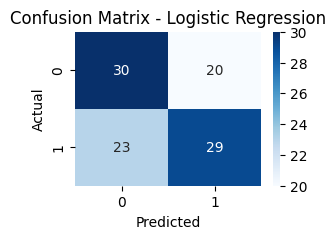

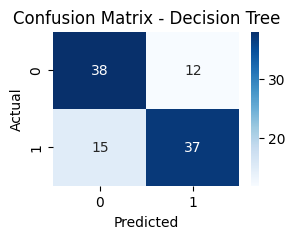

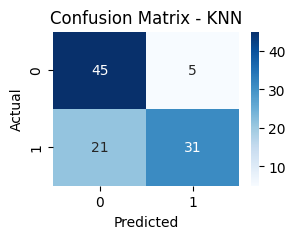

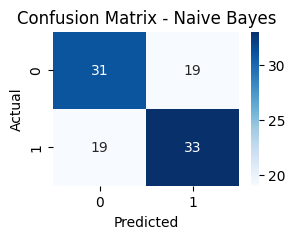

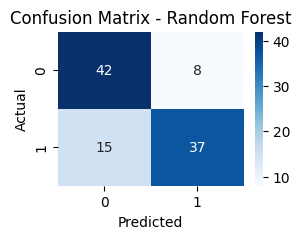

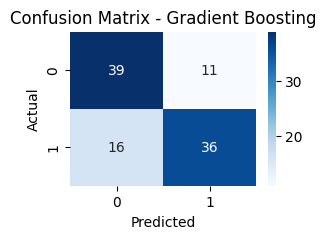

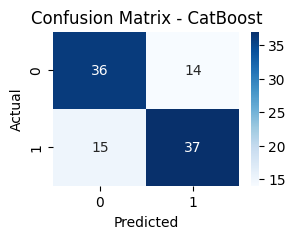

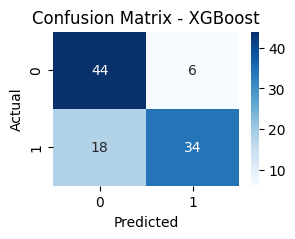

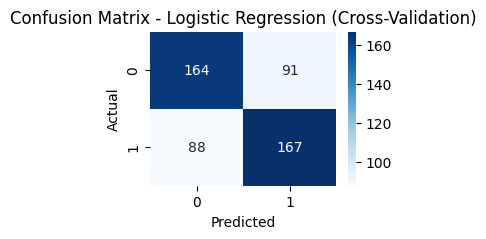

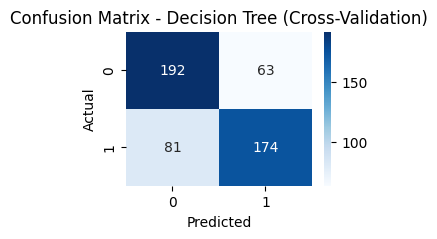

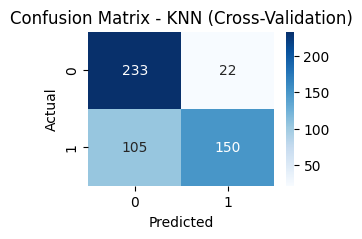

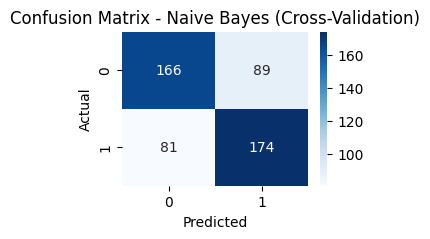

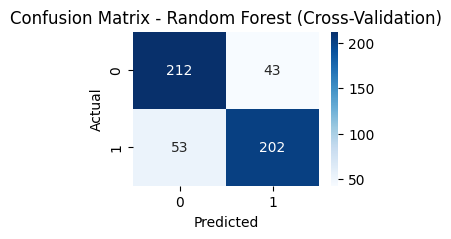

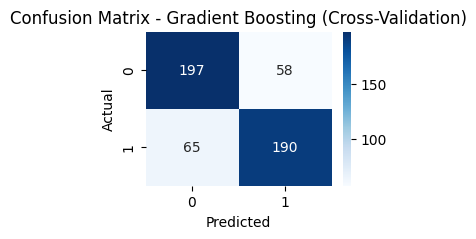

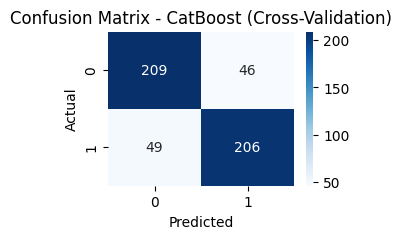

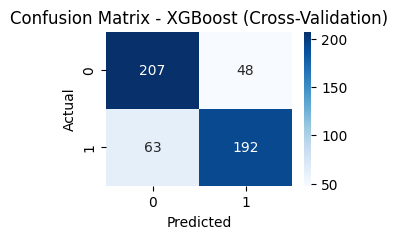

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

for model_name, model in classification_model.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(3, 2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=np.unique(y), yticklabels=np.unique(y))
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

for model_name, model in classification_model_Cress_ValidationK.items():
    y_pred = cross_val_predict(model, X, y, cv=kfold)
    cm = confusion_matrix(y, y_pred)
    plt.figure(figsize=(3, 2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=np.unique(y), yticklabels=np.unique(y))
    plt.title(f"Confusion Matrix - {model_name} (Cross-Validation)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()